# Лабораторная 2. Кластеризация музыкальных треков

Maksim Kostromitin  
Group: J4132


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import adjusted_rand_score, rand_score, silhouette_score
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

SEED = 42

In [2]:
df = pd.read_csv("fma_dataset_filtered.csv")
y = df["genre"]
column_labels = {
    "track_id": "Номер трека", "duration": "Длительность", "tempo": "Темп",
    "danceability": "Танцевальность", "energy": "Энергия звучания", "genre": "Жанр",
    "mfcc_kurtosis_01": "Эксцесс первого коэффициента MFCC",
}
genre_labels = {
    "Hip-Hop": "Хип-хоп", "Folk": "Фолк",
    "Old-Time / Historic": "Старинная музыка", "Classical": "Классическая музыка",
}
display(df[["track_id", "duration", "tempo", "danceability", "energy", "genre"]]
        .head().rename(columns=column_labels).replace({"Жанр": genre_labels}))
display(y.value_counts().rename(index=genre_labels).rename_axis("Жанр").to_frame("Треков"))

,Номер трека,Длительность,Темп,Танцевальность,Энергия звучания,Жанр
0,2,168,165.922,0.675894,0.634476,Хип-хоп
1,3,237,126.957,0.528643,0.817461,Хип-хоп
2,5,206,100.260,0.745566,0.701470,Хип-хоп
3,134,207,114.290,0.513238,0.560410,Хип-хоп
4,139,296,196.961,0.260911,0.607067,Фолк


,Треков
Жанр,
Хип-хоп,910
Фолк,874
Старинная музыка,357
Классическая музыка,265


## Подготовка данных

`track_id` — номер трека, `genre` — жанр для сравнения. Оба столбца исключаю из признаков. Постоянные признаки удаляю, остальные стандартизую: вычитаю среднее и делю на стандартное отклонение, чтобы масштаб не определял расстояния.

В именах признаков `mfcc` — мел-частотные кепстральные коэффициенты (MFCC), описывающие тембр; `chroma_stft` — распределение энергии по нотам; `spectral_contrast` — контраст спектра; `spectral_rolloff` — частота, ниже которой сосредоточена основная энергия сигнала. Окончания `mean`, `median`, `min`, `max`, `kurtosis` обозначают среднее, медиану, минимум, максимум и эксцесс. Имена столбцов сохраняю как в исходном файле.

In [3]:
X = df.drop(columns=["track_id", "genre"])
print(f"Треков: {len(df)}, признаков: {X.shape[1]}")
print(f"Пропусков: {df.isna().sum().sum()}, бесконечных значений: {np.isinf(X).sum().sum()}")
print(f"Повторяющихся номеров треков: {df.track_id.duplicated().sum()}")
constant_columns = X.columns[X.nunique() == 1]
print("Постоянные признаки:", ", ".join(constant_columns))
X = X.drop(columns=constant_columns)
X_scaled = StandardScaler().fit_transform(X)
print("После удаления констант:", X.shape[1], "признаков")

Треков: 2406, признаков: 522
Пропусков: 0, бесконечных значений: 0
Повторяющихся номеров треков: 0
Постоянные признаки: chroma_stft_max_04, chroma_stft_max_05, chroma_stft_max_07, chroma_stft_max_10
После удаления констант: 518 признаков


## Метод главных компонент и t-SNE

Метод главных компонент (PCA) сохраняет направления наибольшего разброса данных. t-SNE строит карту, стараясь разместить похожие объекты рядом.

Для графика PCA беру две компоненты. В t-SNE передаю первые 50 главных компонент, чтобы ускорить расчёт. Жанры задают только цвет точек и не участвуют в построении проекций.

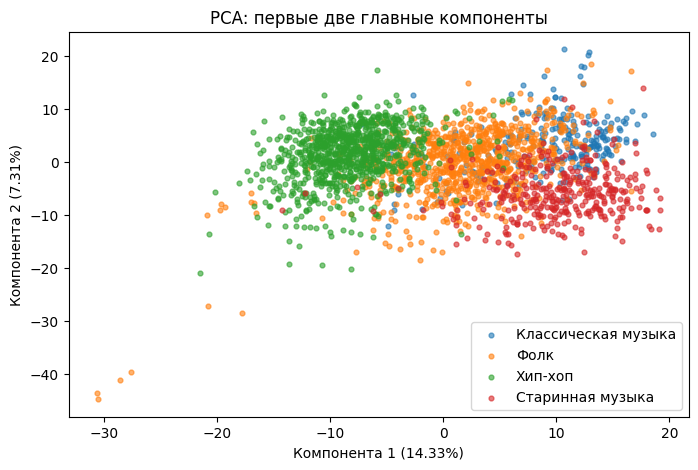

In [4]:
pca = PCA(svd_solver="full")
X_pca = pca.fit_transform(X_scaled)
variance = pca.explained_variance_ratio_
cumulative = variance.cumsum()
X_pca_2d = X_pca[:, :2]

plt.figure(figsize=(8, 5))
for genre in sorted(y.unique()):
    points = X_pca_2d[y == genre]
    plt.scatter(points[:, 0], points[:, 1], s=12, alpha=0.6, label=genre_labels[genre])
plt.xlabel(f"Компонента 1 ({variance[0]:.2%})")
plt.ylabel(f"Компонента 2 ({variance[1]:.2%})")
plt.title("PCA: первые две главные компоненты")
plt.legend()
plt.show()

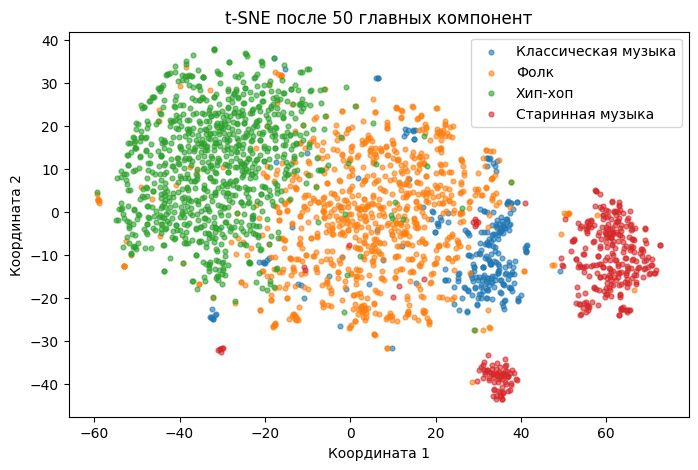

In [5]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    max_iter=1000,
    random_state=SEED,
)
X_tsne = tsne.fit_transform(X_pca[:, :50])

plt.figure(figsize=(8, 5))
for genre in sorted(y.unique()):
    points = X_tsne[y == genre]
    plt.scatter(points[:, 0], points[:, 1], s=12, alpha=0.6, label=genre_labels[genre])
plt.xlabel("Координата 1")
plt.ylabel("Координата 2")
plt.title("t-SNE после 50 главных компонент")
plt.legend()
plt.show()

Считаю долю соседей того же жанра среди десяти ближайших. Показатель сохранения соседств (`trustworthiness`) оценивает, насколько близкие точки на проекции были близки в исходном пространстве: чем ближе к 1, тем лучше.

In [6]:
neighbor_rows = []
for name, points in [
    ("Исходные признаки", X_scaled),
    ("PCA, 2 компоненты", X_pca_2d),
    ("PCA(50) + t-SNE", X_tsne),
]:
    neighbors = NearestNeighbors(n_neighbors=10).fit(points)
    ids = neighbors.kneighbors(return_distance=False)
    same_genre = (y.to_numpy()[ids] == y.to_numpy()[:, None]).mean()
    local_score = np.nan
    if name != "Исходные признаки":
        local_score = trustworthiness(X_scaled, points, n_neighbors=10)
    neighbor_rows.append(
        {
            "Представление": name,
            "Trustworthiness": local_score,
            "Соседи того же жанра, %": 100 * same_genre,
        }
    )

neighbor_scores = pd.DataFrame(neighbor_rows).set_index("Представление")
display(neighbor_scores.rename(columns={"Trustworthiness": "Сохранение соседств"})
        .rename(index={"PCA(50) + t-SNE": "50 главных компонент → t-SNE"})
        .round(4).fillna("—"))

,Сохранение соседств,"Соседи того же жанра, %"
Представление,,
Исходные признаки,—,85.6193
"PCA, 2 компоненты",0.7635,70.6193
50 главных компонент → t-SNE,0.9016,86.9244


### 6.1. Насколько хорошо видны жанры

Жанры частично перекрываются. t-SNE лучше сохраняет локальные соседства, и рядом чаще оказываются треки одного жанра. PCA сохраняет направления наибольшей дисперсии, но двух компонент здесь мало. t-SNE тоже не передаёт всё распределение: размеры групп и расстояния между далёкими группами могут искажаться.

## Дисперсия по главным компонентам

Первый график показывает вклад каждой из 518 компонент, второй — накопленную долю дисперсии.

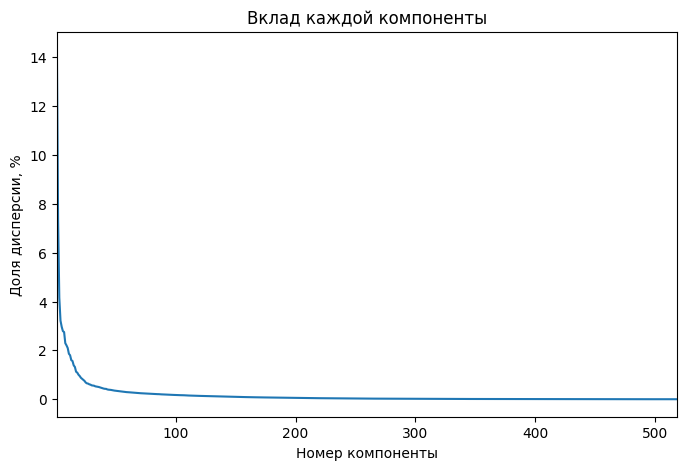

In [7]:
components = np.arange(1, len(variance) + 1)
plt.figure(figsize=(8, 5))
plt.plot(components, 100 * variance)
plt.xlim(1, len(variance))
plt.xlabel("Номер компоненты")
plt.ylabel("Доля дисперсии, %")
plt.title("Вклад каждой компоненты")
plt.show()

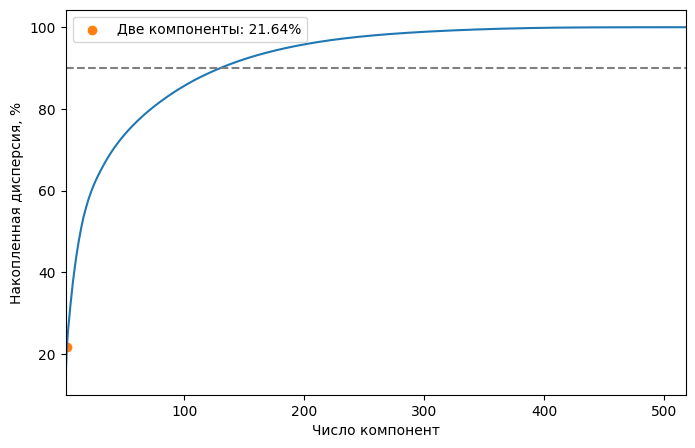

,Компонент,"Доля дисперсии, %"
0,2,21.641
1,50,73.678
2,130,90.012
3,187,95.053
4,518,100.000


In [8]:
plt.figure(figsize=(8, 5))
plt.plot(components, 100 * cumulative)
plt.scatter(
    2,
    100 * cumulative[1],
    color="tab:orange",
    label=f"Две компоненты: {cumulative[1]:.2%}",
)
plt.axhline(90, color="gray", linestyle="--")
plt.xlim(1, len(variance))
plt.xlabel("Число компонент")
plt.ylabel("Накопленная дисперсия, %")
plt.legend()
plt.show()

n90 = int(np.searchsorted(cumulative, 0.90)) + 1
n95 = int(np.searchsorted(cumulative, 0.95)) + 1
counts = np.array([2, 50, n90, n95, len(variance)])
display(pd.DataFrame({
    "Компонент": counts,
    "Доля дисперсии, %": (100 * cumulative[counts - 1]).round(3),
}))

### 6.2. Доля дисперсии в двух компонентах

Первые две компоненты сохраняют **21,64%** дисперсии стандартизованных признаков. Для 90% нужны 130 компонент; первые 50, использованные перед t-SNE, сохраняют 73,68%.

## Метод k-средних (K-Means)

Метод k-средних уменьшает сумму квадратов расстояний от объектов до центров их кластеров. Кластеры строю по всем 518 стандартизованным признакам.

Силуэт сравнивает расстояния внутри группы и до соседней группы. Индекс Рэнда (`Rand Index`) показывает долю пар треков, для которых кластеры и жанры согласны: оба трека вместе или раздельно. Скорректированный индекс Рэнда (ARI) учитывает случайные совпадения. Жанры нужны только для этих двух индексов.

In [9]:
cluster_labels = {}
rows = []
for k in range(2, 7):
    model = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    labels = model.fit_predict(X_scaled)
    cluster_labels[k] = labels
    rows.append({
        "k": k,
        "Silhouette": silhouette_score(X_scaled, labels),
        "Rand Index": rand_score(y, labels),
        "Adjusted Rand": adjusted_rand_score(y, labels),
        "Минимальный кластер": np.bincount(labels).min(),
    })

scores = pd.DataFrame(rows).set_index("k")
k_sil = int(scores["Silhouette"].idxmax())
k_rand = int(scores["Rand Index"].idxmax())
display(scores.rename_axis("Число кластеров").rename(columns={
    "Silhouette": "Силуэт", "Rand Index": "Индекс Рэнда",
    "Adjusted Rand": "Скорректированный индекс Рэнда",
}).round(6))
print(f"Лучшее число кластеров: по силуэту — {k_sil}, по индексу Рэнда — {k_rand}")

Лучшее число кластеров: по силуэту — 2, по индексу Рэнда — 6


,Силуэт,Индекс Рэнда,Скорректированный индекс Рэнда,Минимальный кластер
Число кластеров,,,,
2,0.109617,0.680312,0.360527,1198
3,0.089893,0.785551,0.527104,411
4,0.075250,0.773686,0.453345,389
5,0.071848,0.804683,0.507060,254
6,0.072137,0.804779,0.506193,4


In [10]:
sizes = pd.Series(cluster_labels[k_rand]).value_counts()
small_cluster = int(sizes.idxmin())
small_tracks = df.loc[
    cluster_labels[k_rand] == small_cluster, ["track_id", "genre", "mfcc_kurtosis_01"]
]
display(small_tracks.reset_index(drop=True).rename(columns=column_labels)
        .replace({"Жанр": genre_labels}))

,Номер трека,Жанр,Эксцесс первого коэффициента MFCC
0,3315,Фолк,497.851288
1,3363,Фолк,567.529053
2,3364,Фолк,986.124573
3,3365,Фолк,627.702271


### 6.3. Как выбрать число кластеров

Силуэт максимален при двух кластерах (0,110), но разделение слабое. Он оценивает компактность групп и расстояния между ними, поэтому одного силуэта для поиска жанров недостаточно.

Для сравнения с жанрами уместнее индекс Рэнда. Максимум — при шести кластерах (0,804779), почти столько же дают пять (0,804683). У шести кластеров один состоит всего из четырёх треков жанра «фолк». Индекс Рэнда учитывает и пары из разных групп, поэтому высокий результат не гарантирует совпадения с жанрами. С поправкой на случайные совпадения (ARI) максимум у трёх кластеров.

## 6.4. Рекомендации без жанров

Ищу ближайшие треки по аудиопризнакам: стандартизация, 130 компонент PCA (90% дисперсии), евклидово расстояние. Ниже — пять соседей первого трека без самой песни. Качество рекомендаций нужно проверить по оценкам слушателей.

In [11]:
X_recommend = X_pca[:, :n90]
query_row = 0
neighbor_model = NearestNeighbors(metric="euclidean").fit(X_recommend)
distances, indices = neighbor_model.kneighbors(
    X_recommend[query_row : query_row + 1], n_neighbors=6
)
keep = indices[0] != query_row
ids = indices[0][keep][:5]
recommendations = df.iloc[ids][["track_id", "tempo", "energy"]].copy()
recommendations["Расстояние"] = distances[0][keep][:5]
print("Исходный трек:", df.track_id.iloc[query_row])
display(recommendations.reset_index(drop=True).rename(columns=column_labels).round(4))

Исходный трек: 2


,Номер трека,Темп,Энергия звучания,Расстояние
0,7492,92.967,0.8028,15.4846
1,32484,93.960,0.4528,15.5127
2,11854,92.525,0.5955,16.3107
3,32480,146.513,0.4458,16.5345
4,15209,112.047,0.4535,17.2018


## 6.5*. Какие признаки различают кластеры

Делю межкластерную сумму квадратов каждого признака на полную. Чем больше доля, тем сильнее различаются средние значения в кластерах.

In [12]:
for k in [k_sil, k_rand]:
    cluster_means = X.groupby(cluster_labels[k]).transform("mean")
    share = cluster_means.var() / X.var()
    display(share.nlargest(8).to_frame(f"Доля межкластерного разброса, k={k}"))

,"Доля межкластерного разброса, k=2"
energy,0.480602
mfcc_median_10,0.458798
mfcc_mean_10,0.450791
spectral_contrast_mean_04,0.436714
spectral_contrast_median_04,0.433527
mfcc_max_06,0.431605
spectral_contrast_mean_03,0.431270
mfcc_mean_06,0.430083


,"Доля межкластерного разброса, k=6"
mfcc_kurtosis_01,0.903642
chroma_stft_min_11,0.855632
chroma_stft_min_10,0.794534
mfcc_mean_04,0.691112
mfcc_median_04,0.684424
spectral_rolloff_min_01,0.657499
mfcc_max_04,0.650134
mfcc_median_08,0.646101


При двух кластерах лидирует энергия трека (`energy`): межкластерные различия объясняют **48,1%** её разброса. При шести — эксцесс первого MFCC-коэффициента (`mfcc_kurtosis_01`), **90,4%**. Особенно велики его значения у четырёх треков из маленького кластера.

Это описание найденного разбиения, а не доказательство, что один признак определяет кластеры: часть признаков связана между собой.

## Выводы

Две главные компоненты сохраняют 21,64% дисперсии. На карте t-SNE жанры различимы лучше. По силуэту лучше 2 кластера, по индексу Рэнда — 6, но точного совпадения с жанрами нет.